# CsI–SiPM：时间协方差能否解释F202带宽差异？

2026-11-02。先完成英文提交 **94aa3ba**（`Decompose CsI QDC tails and fluctuation variance residuals`），并已push、核对GitHub main与本地SHA一致；此前的独立Geant4统计提交d481527也一并推送。本笔记是该提交之后的继续研究。

承接[QDC尾部与F202残差分解](codex_0001_csi_qdc_fluctuation_residuals.ipynb)：晚段扩展谱的Co/Am F202事件SD比为1.232/1.201，超额方差主要位于信号窗。这里进一步问：**这些差异是否已由完整波形向量的均值、时间协方差解释，还是还有二阶闭合之外的差异？**

全部原ADC、事件ID、Q支持、目标权重、三个既有响应及PID定义固定。新增Geant4母事件、读出重放、实验事件均为0，没有根据本轮结果调参或剔除事件。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/gaussian_closure_20261102'
def read(path):return json.loads(Path(path).read_text())
def fmt(x):return '不可估计' if x is None else f'{x:.3f}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');e=read(OUT/'analysis.json');decision=read(OUT/'decision.json')
variants=p['variants'];labels={'frozen':'原冻结','inherited_CV_fit':'RC+原谱','spectrum_CV_fit':'RC+扩展谱'}
def rec(g,v='spectrum_CV_fit',cond='Q_half',norm='event_mu',scale=202):return g['cohorts'][v]['contrasts'][cond][norm][str(scale)]
print('方案冻结提交:',p['checkpoint_commit'],'已核对输入:',len(p['inputs_sha256']))
display(Markdown(decision['conclusion_zh']))

方案冻结提交: 94aa3ba47739d2661ecbe94df42e5103b0d174e4 已核对输入: 339


二阶时间协方差的Gaussian闭合与实际F202离散度给出了不同的MC/实测关系。应将二阶结构与事件间高阶/混合结构分别约束，不能仅靠一个噪声幅度倍率认定PID带宽已经匹配。

## 1. 从原ADC到一个精确的二次型

保留原25/51/101点中心滑动均值高通残差（50/102/202 ns）、原`t10`定位和前200点/后1000点窗口。每个窗内先减去该窗均值，记残差为$r_{\rm post},r_{\rm pre}$，则

\[
X=\left(\frac{r_{\rm post}}{\sqrt{999\mu}},\frac{r_{\rm pre}}{\sqrt{199\mu}}\right),\quad
A=\operatorname{diag}(+1_{1000},-1_{200}),\quad F=X^TAX.
\]

分母$\mu$为该事件信号窗平均ADC。这个等式与原`ddof=1`、`F=(Vpost−Vpre)/mu`逐事件完全相等。固定分母对照只将μ换成父记录中对折实测的同Q箱均值μ₀，不改ADC或正式PID。

若X服从同一多元Gaussian分布，均值m、协方差C、二阶矩M=C+mmᵀ，其二次型方差由一、二阶矩决定：

\[
V_G=2\operatorname{tr}(ACAC)+4m^TACAm
=2\{\operatorname{tr}(AMAM)-(m^TAm)^2\}.
\]

这里保留完整时间矩阵和前/后窗交叉项，无平稳性、白噪声或对角协方差假设。对实际非Gaussian向量也计算此闭合量，再把`实际方差−闭合方差`称作**余项**。余项可能来自高阶累积量、信号/幅度/响应混合、选择约束或事件相关性，不等于已识别的某一种物理噪声。


|晚段run|响应|F202指标|点值|条件95%重抽样范围（有效次数）|
|---|---|---|---|---|
|3|原冻结|observed_SD_ratio|1.251|[1.187, 1.345] (512/512)|
|3|原冻结|gaussian_SD_ratio|1.014|[0.967, 1.051] (503/512)|
|3|原冻结|gaussian_excess_over_data|0.030|[-0.073, 0.117] (503/512)|
|3|原冻结|remainder_excess_over_data|0.535|[0.386, 0.744] (503/512)|
|3|RC+原谱|observed_SD_ratio|1.224|[1.161, 1.317] (512/512)|
|3|RC+原谱|gaussian_SD_ratio|0.992|[0.945, 1.028] (503/512)|
|3|RC+原谱|gaussian_excess_over_data|-0.017|[-0.119, 0.062] (503/512)|
|3|RC+原谱|remainder_excess_over_data|0.516|[0.372, 0.721] (503/512)|
|3|RC+扩展谱|observed_SD_ratio|1.232|[1.168, 1.326] (512/512)|
|3|RC+扩展谱|gaussian_SD_ratio|0.998|[0.951, 1.034] (503/512)|
|3|RC+扩展谱|gaussian_excess_over_data|-0.004|[-0.107, 0.076] (503/512)|
|3|RC+扩展谱|remainder_excess_over_data|0.522|[0.377, 0.729] (503/512)|
|12|原冻结|observed_SD_ratio|1.083|[1.012, 1.185] (512/512)|
|12|原冻结|gaussian_SD_ratio|0.908|[0.860, 0.962] (512/512)|
|12|原冻结|gaussian_excess_over_data|-0.211|[-0.340, -0.087] (512/512)|
|12|原冻结|remainder_excess_over_data|0.383|[0.220, 0.631] (512/512)|
|12|RC+原谱|observed_SD_ratio|1.205|[1.127, 1.317] (512/512)|
|12|RC+原谱|gaussian_SD_ratio|1.044|[0.990, 1.106] (512/512)|
|12|RC+原谱|gaussian_excess_over_data|0.106|[-0.027, 0.256] (512/512)|
|12|RC+原谱|remainder_excess_over_data|0.345|[0.156, 0.593] (512/512)|
|12|RC+扩展谱|observed_SD_ratio|1.201|[1.122, 1.312] (512/512)|
|12|RC+扩展谱|gaussian_SD_ratio|1.039|[0.985, 1.100] (512/512)|
|12|RC+扩展谱|gaussian_excess_over_data|0.094|[-0.038, 0.242] (512/512)|
|12|RC+扩展谱|remainder_excess_over_data|0.348|[0.157, 0.593] (512/512)|

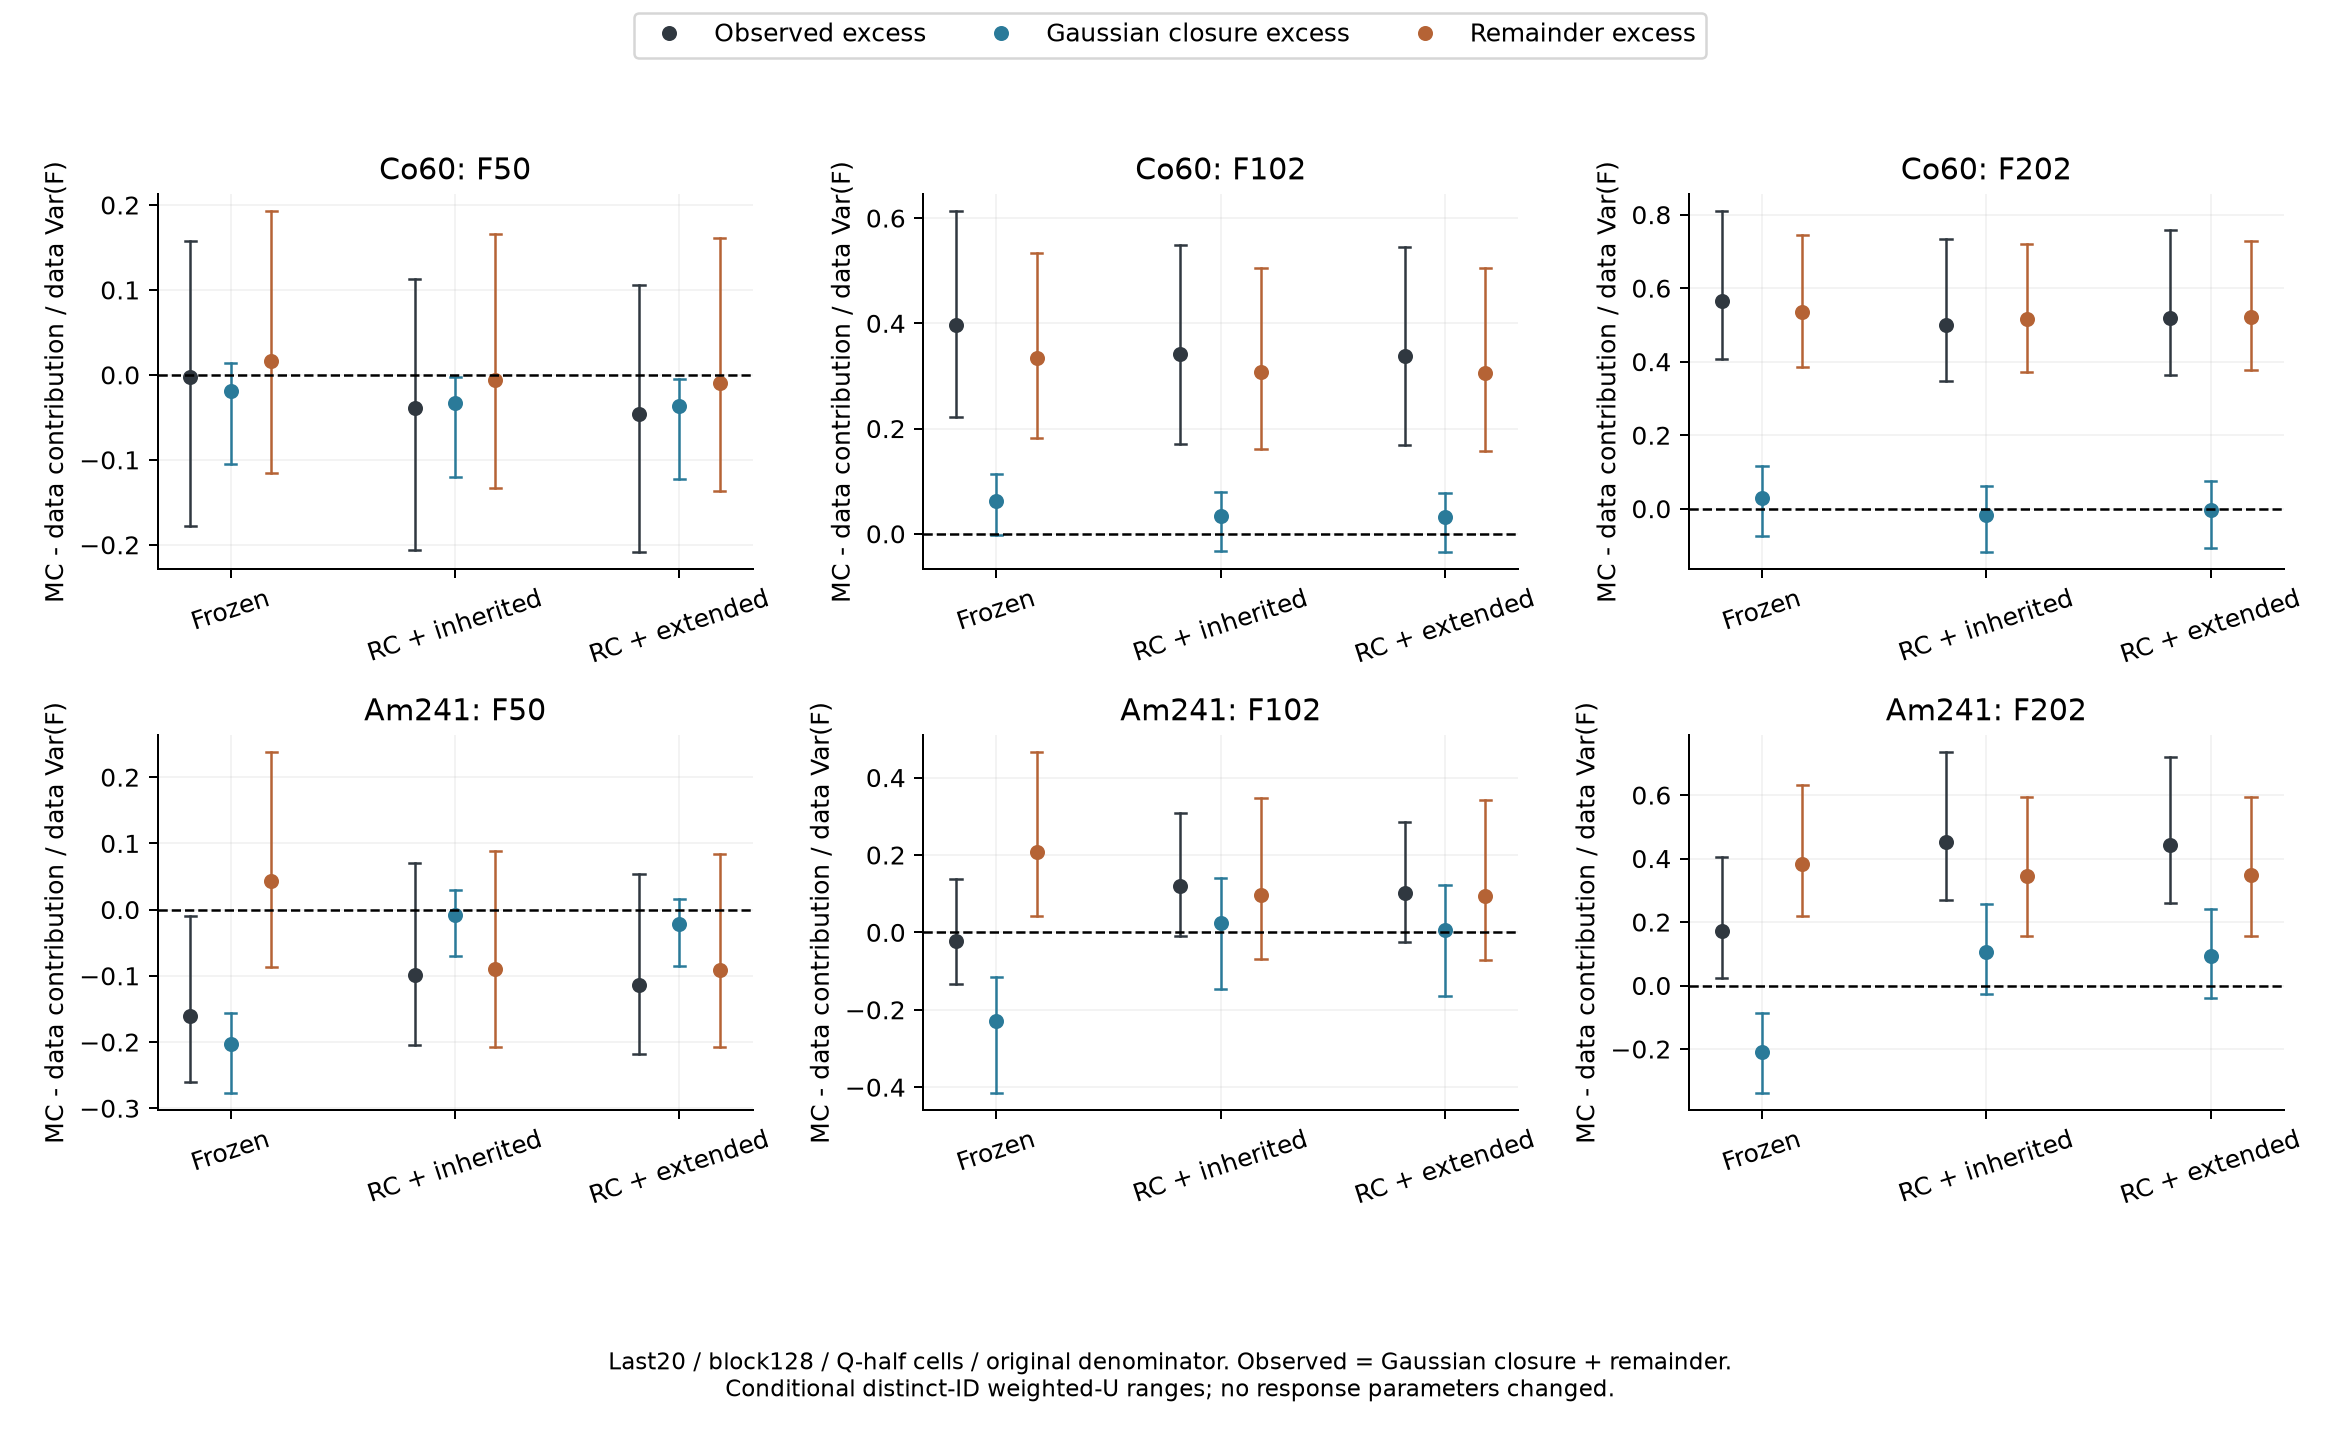

In [2]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128']
    for v in variants:
        r=rec(g,v)
        for name in ['observed_SD_ratio','gaussian_SD_ratio','gaussian_excess_over_data','remainder_excess_over_data']:
            rows.append([run,labels[v],name,fmt(r['point'][name]),ci(r['CI95'][name])])
display(Markdown(table(['晚段run','响应','F202指标','点值','条件95%重抽样范围（有效次数）'],rows)))
display(Image(filename=str(OUT/'figures/gaussian_excess_decomposition.png')))

所有方差仍为**原Q箱内方差，再在支持箱之间等权**。主分析的Gaussian闭合在Q半箱内计算，加回与实测直接方差相同的半箱均值差项；这个均值项含有限样本噪声，不是预测出来的物理漂移。

主分析保留响应折混合，细分“Q半箱×响应折”是敏感性检查。在看新派生结果前，样本计数已显示Co晚段块128有一个3事件细格，中段还有2事件细格；这些细分整体结果不可估计，不能删掉该箱后报告剩余箱。主分析所有原支持箱保留。


|run|分母|条件格|直接SD比|Gaussian SD比|余项超额/实测方差|重抽样范围|
|---|---|---|---|---|---|---|
|3|event_mu|Q_half|1.232|0.998|0.522|[0.377, 0.729] (503/512)|
|3|event_mu|Q_half_fold|1.232|不可估计|不可估计|不可估计|
|3|opposite_fold_mu0|Q_half|1.212|0.993|0.483|[0.338, 0.689] (503/512)|
|3|opposite_fold_mu0|Q_half_fold|1.212|不可估计|不可估计|不可估计|
|12|event_mu|Q_half|1.201|1.039|0.348|[0.157, 0.593] (512/512)|
|12|event_mu|Q_half_fold|1.201|1.040|0.345|[0.160, 0.595] (463/512)|
|12|opposite_fold_mu0|Q_half|1.107|0.999|0.227|[0.084, 0.420] (512/512)|
|12|opposite_fold_mu0|Q_half_fold|1.107|1.002|0.222|[0.075, 0.431] (463/512)|

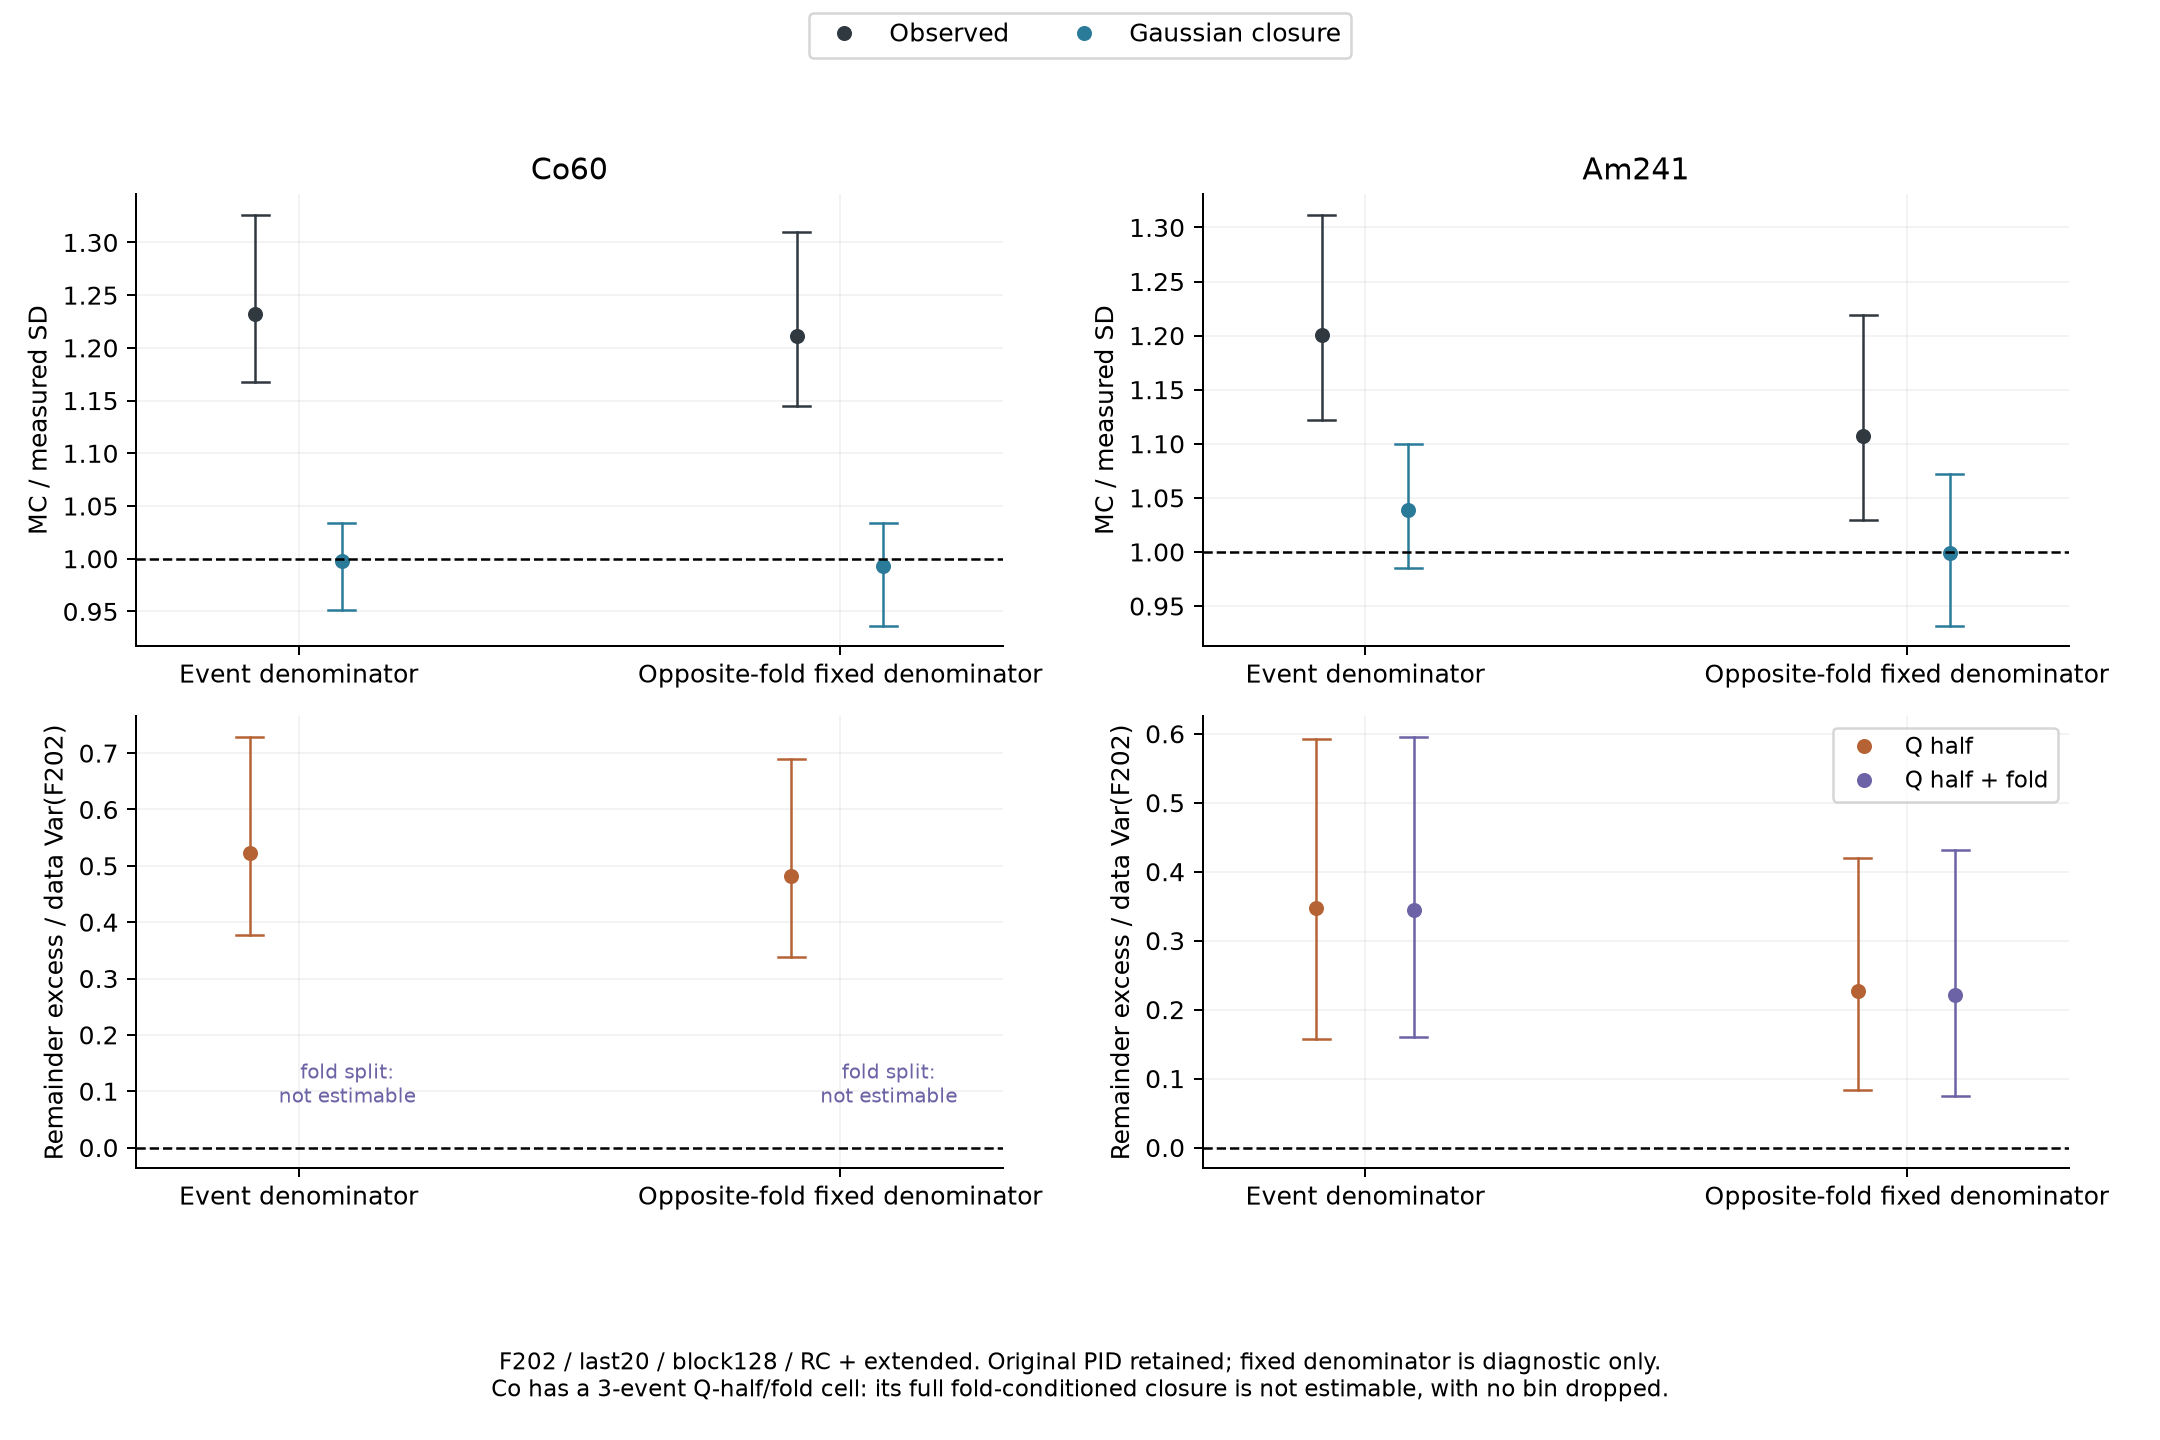

In [3]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128']
    for norm in p['normalizations']:
        for cond in p['conditioning']:
            r=rec(g,cond=cond,norm=norm)
            rows.append([run,norm,cond,fmt(r['point']['observed_SD_ratio']),fmt(r['point']['gaussian_SD_ratio']),
                         fmt(r['point']['remainder_excess_over_data']),ci(r['CI95']['remainder_excess_over_data'])])
display(Markdown(table(['run','分母','条件格','直接SD比','Gaussian SD比','余项超额/实测方差','重抽样范围'],rows)))
display(Image(filename=str(OUT/'figures/gaussian_normalization_controls.png')))

## 2. 有限样本偏差与不同原事件的U统计

每个向量有1200个样点，而部分格只有十几个事件。直接把样本协方差代入$V_G$会引入自配对项，不能把它视为可靠的总体Gaussian方差估计。

令$K_{ij}=X_i^TAX_j$。不同事件的$E(K_{ij}^2)=\operatorname{tr}(AMAM)$，四个不同事件的$E(K_{ij}K_{kl})=(m^TAm)^2$，因此可分别用不同原ID的有序对/四元组估计这两项。无权重时记对角置零的K的总和为S、元素平方和为T、行和平方之和为R，则

\[
\widehat V_G=2\left\{\frac{T}{n(n-1)}-\frac{S^2-4R+2T}{n(n-1)(n-2)(n-3)}\right\}.
\]

该U式的总体无偏性质依赖格内独立同分布假设，真实采集数据不保证满足。点估计或某次抽样少于4个不同原ID时不可估计；负U估计不截成零，无法开平方时不报告Gaussian SD比。与父分析的有偏经验方差比较时，格内乘`(N−1)/N`，再加回完全相同的格间均值项。

沿用父分析512组实验原索引块抽样、4批完整母事件抽样的**相同计数和随机流**。U项使用这些计数作为不同原ID对/四元组的乘积权重，分母也是不同原ID的权重和；重复副本不能变成“独立事件”。通常的复制样本直接方差则保持父统计口径。

这些区间是固定参数下的加权U重抽样范围，没有证明覆盖率，也未计入拟合、系统误差或多重比较。稀疏格会令部分抽样不可估计，必须同时看有效次数。`plugin−U`只是有限样本自配对敏感性的诊断；其重抽样范围会因重复权重而偏移，**不能解读成总体偏差的置信区间**。


In [4]:
display(Markdown('独立算法检查：'))
display(read(OUT/'algebra_tests.json'))
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128']
    for v in ['data',*variants]:
        s=g['cohorts'][v]['summary']['Q_half']['event_mu']['202']
        rows.append([run,'实测' if v=='data' else labels[v],*[f'{s[k]:.6g}' if s[k] is not None else '不可估计' for k in
            ['observed','gaussian_U','gaussian_plugin','fourth_remainder']],fmt(s['plugin_bias']/s['observed'])])
display(Markdown(table(['run','队列','直接方差','不同ID闭合','直接代入闭合','余项','(直接代入−U)/直接方差'],rows)))

独立算法检查：

{'brute_force_weighted_pair_quad_checks': 18,
 'dense_covariance_checks': 6,
 'gaussian_population_variance': 26.81020000000001,
 'gaussian_U_estimate': 26.387238009166857,
 'three_distinct_IDs_unestimable': True}

|run|队列|直接方差|不同ID闭合|直接代入闭合|余项|(直接代入−U)/直接方差|
|---|---|---|---|---|---|---|
|3|实测|0.00405528|0.00419137|0.00841112|-0.00013609|1.041|
|3|原冻结|0.00634528|0.00431296|0.00537458|0.00203232|0.167|
|3|RC+原谱|0.00607823|0.00412362|0.00514297|0.00195462|0.168|
|3|RC+扩展谱|0.0061544|0.00417379|0.00519973|0.00198061|0.167|
|12|实测|0.0322324|0.038499|0.0683432|-0.00626661|0.926|
|12|原冻结|0.037793|0.0317118|0.0390052|0.00608121|0.193|
|12|RC+原谱|0.0467979|0.0419283|0.0490436|0.00486961|0.152|
|12|RC+扩展谱|0.0464922|0.0415446|0.0485489|0.00494761|0.151|

## 3. 每个电荷箱都检查，并报告稀疏格

以下逐箱比较仍用原Q半箱目标质量，Co保留6箱，Am保留前3箱。不是按本轮结果挑箱，也没有新增粒子真值标签。


|run|Q箱|半箱|实测事件|折0|折1|目标质量|
|---|---|---|---|---|---|---|
|3|0|0|14|5|9|0.494|
|3|0|1|14|3|11|0.506|
|3|1|0|24|12|12|0.496|
|3|1|1|30|18|12|0.504|
|3|2|0|58|29|29|0.500|
|3|2|1|48|26|22|0.500|
|3|3|0|122|66|56|0.499|
|3|3|1|87|51|36|0.501|
|3|4|0|136|62|74|0.500|
|3|4|1|138|69|69|0.500|
|3|5|0|75|41|34|0.500|
|3|5|1|75|44|31|0.500|
|12|0|0|75|37|38|0.499|
|12|0|1|79|39|40|0.501|
|12|1|0|42|20|22|0.499|
|12|1|1|57|27|30|0.501|
|12|2|0|31|18|13|0.500|
|12|2|1|32|18|14|0.500|

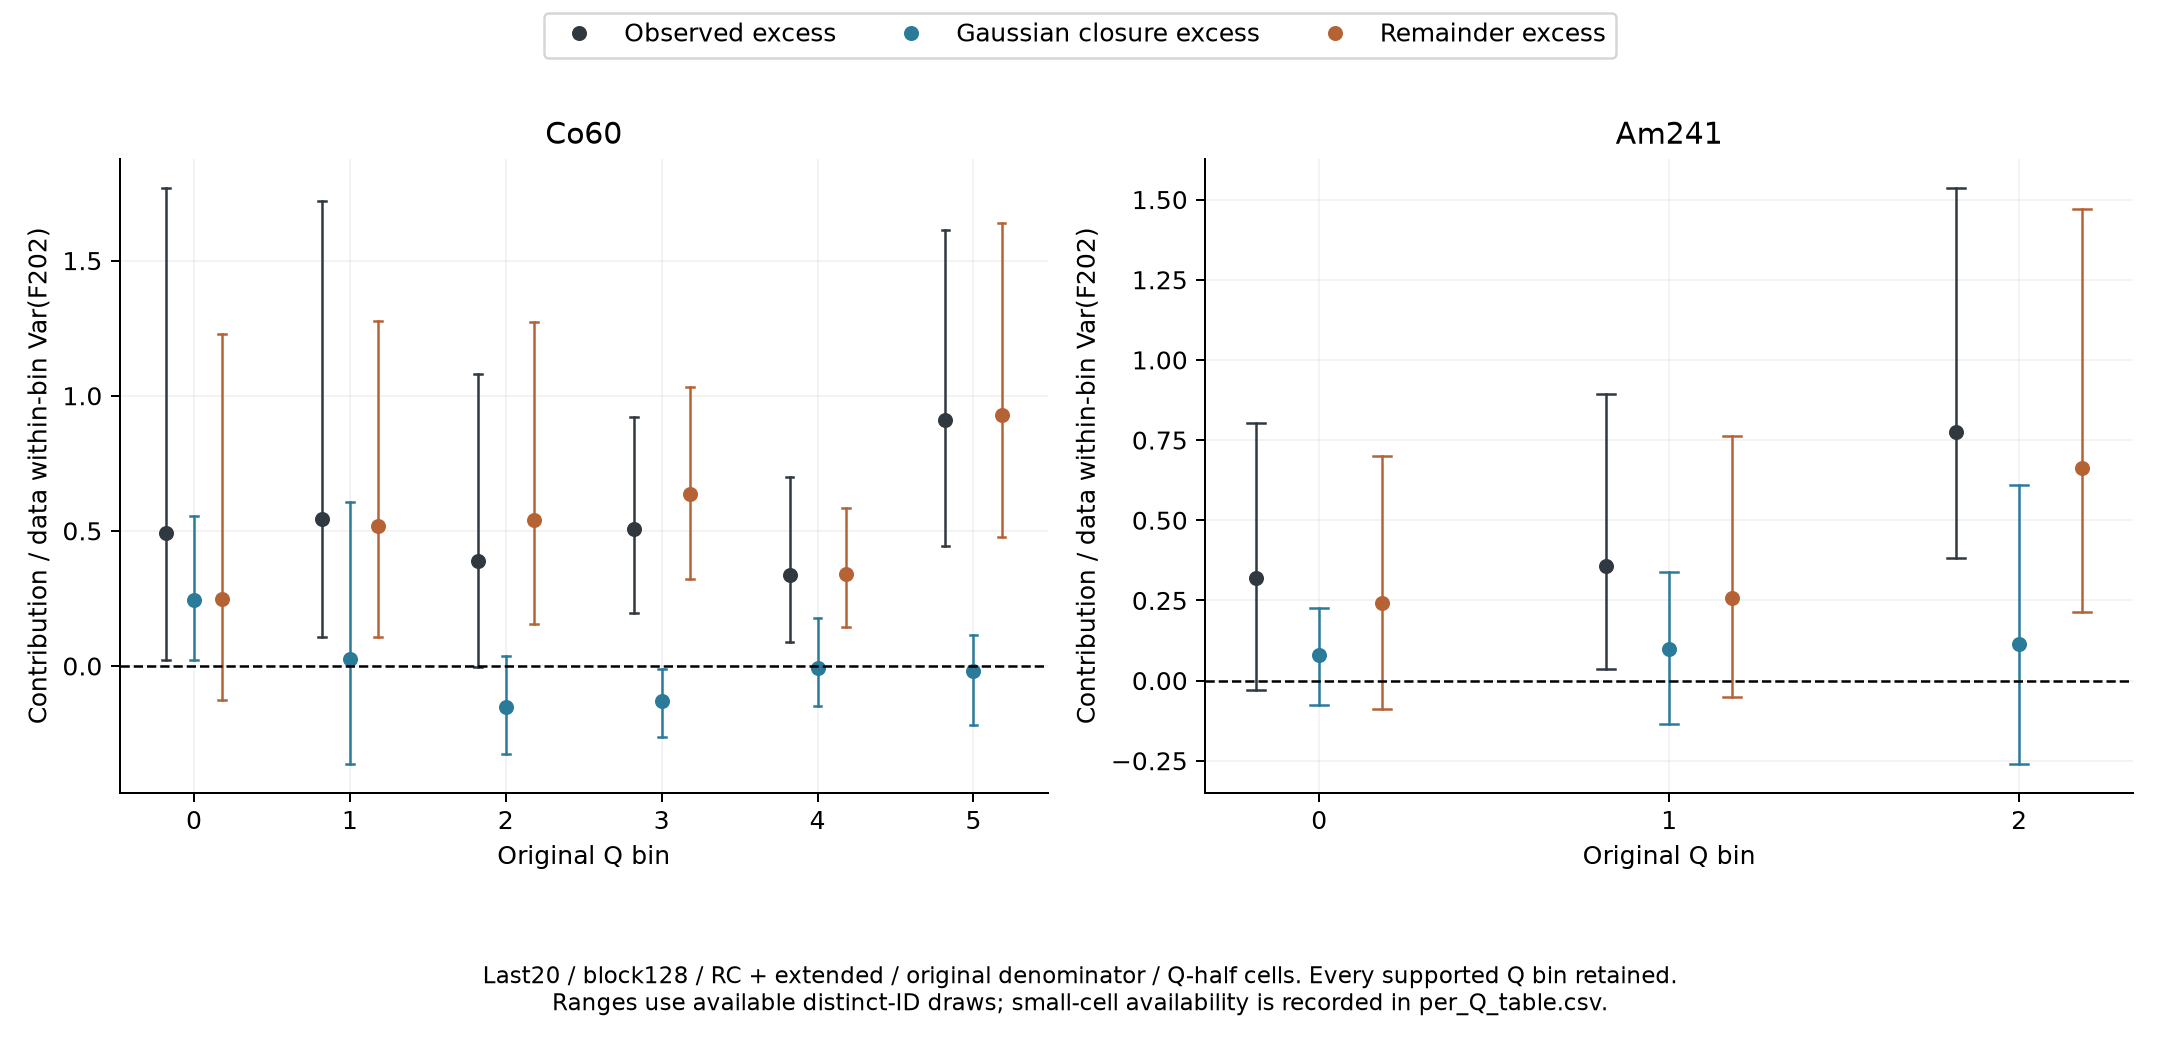

In [5]:
rows=[]
for run in [3,12]:
    g=e['groups'][f'run{run}_last20']['128']
    for c in g['cohorts']['data']['cells']:
        rows.append([run,c['Q_bin'],c['half'],c['events'],*c['fold_counts'],fmt(c['target'])])
display(Markdown(table(['run','Q箱','半箱','实测事件','折0','折1','目标质量'],rows)))
display(Image(filename=str(OUT/'figures/gaussian_charge_controls.png')))

## 4. 描述性的时间协方差曲线

对Q半箱内事件在每个样点减去跨事件均值，平均后窗的`Cov(t,t+lag)`，除以该格的平均零延迟方差，再按冻结半箱/Q权重汇总。使用完整原窗，但图只展示预先固定的9个延迟。

曲线接近或Gaussian SD比接近1，不代表两个完整协方差矩阵等效；只意味着所报告的投影/二次型关系接近。曲线不是平稳噪声功率谱，不直接给出器件相关时间，也不带新的拟合或误差带。


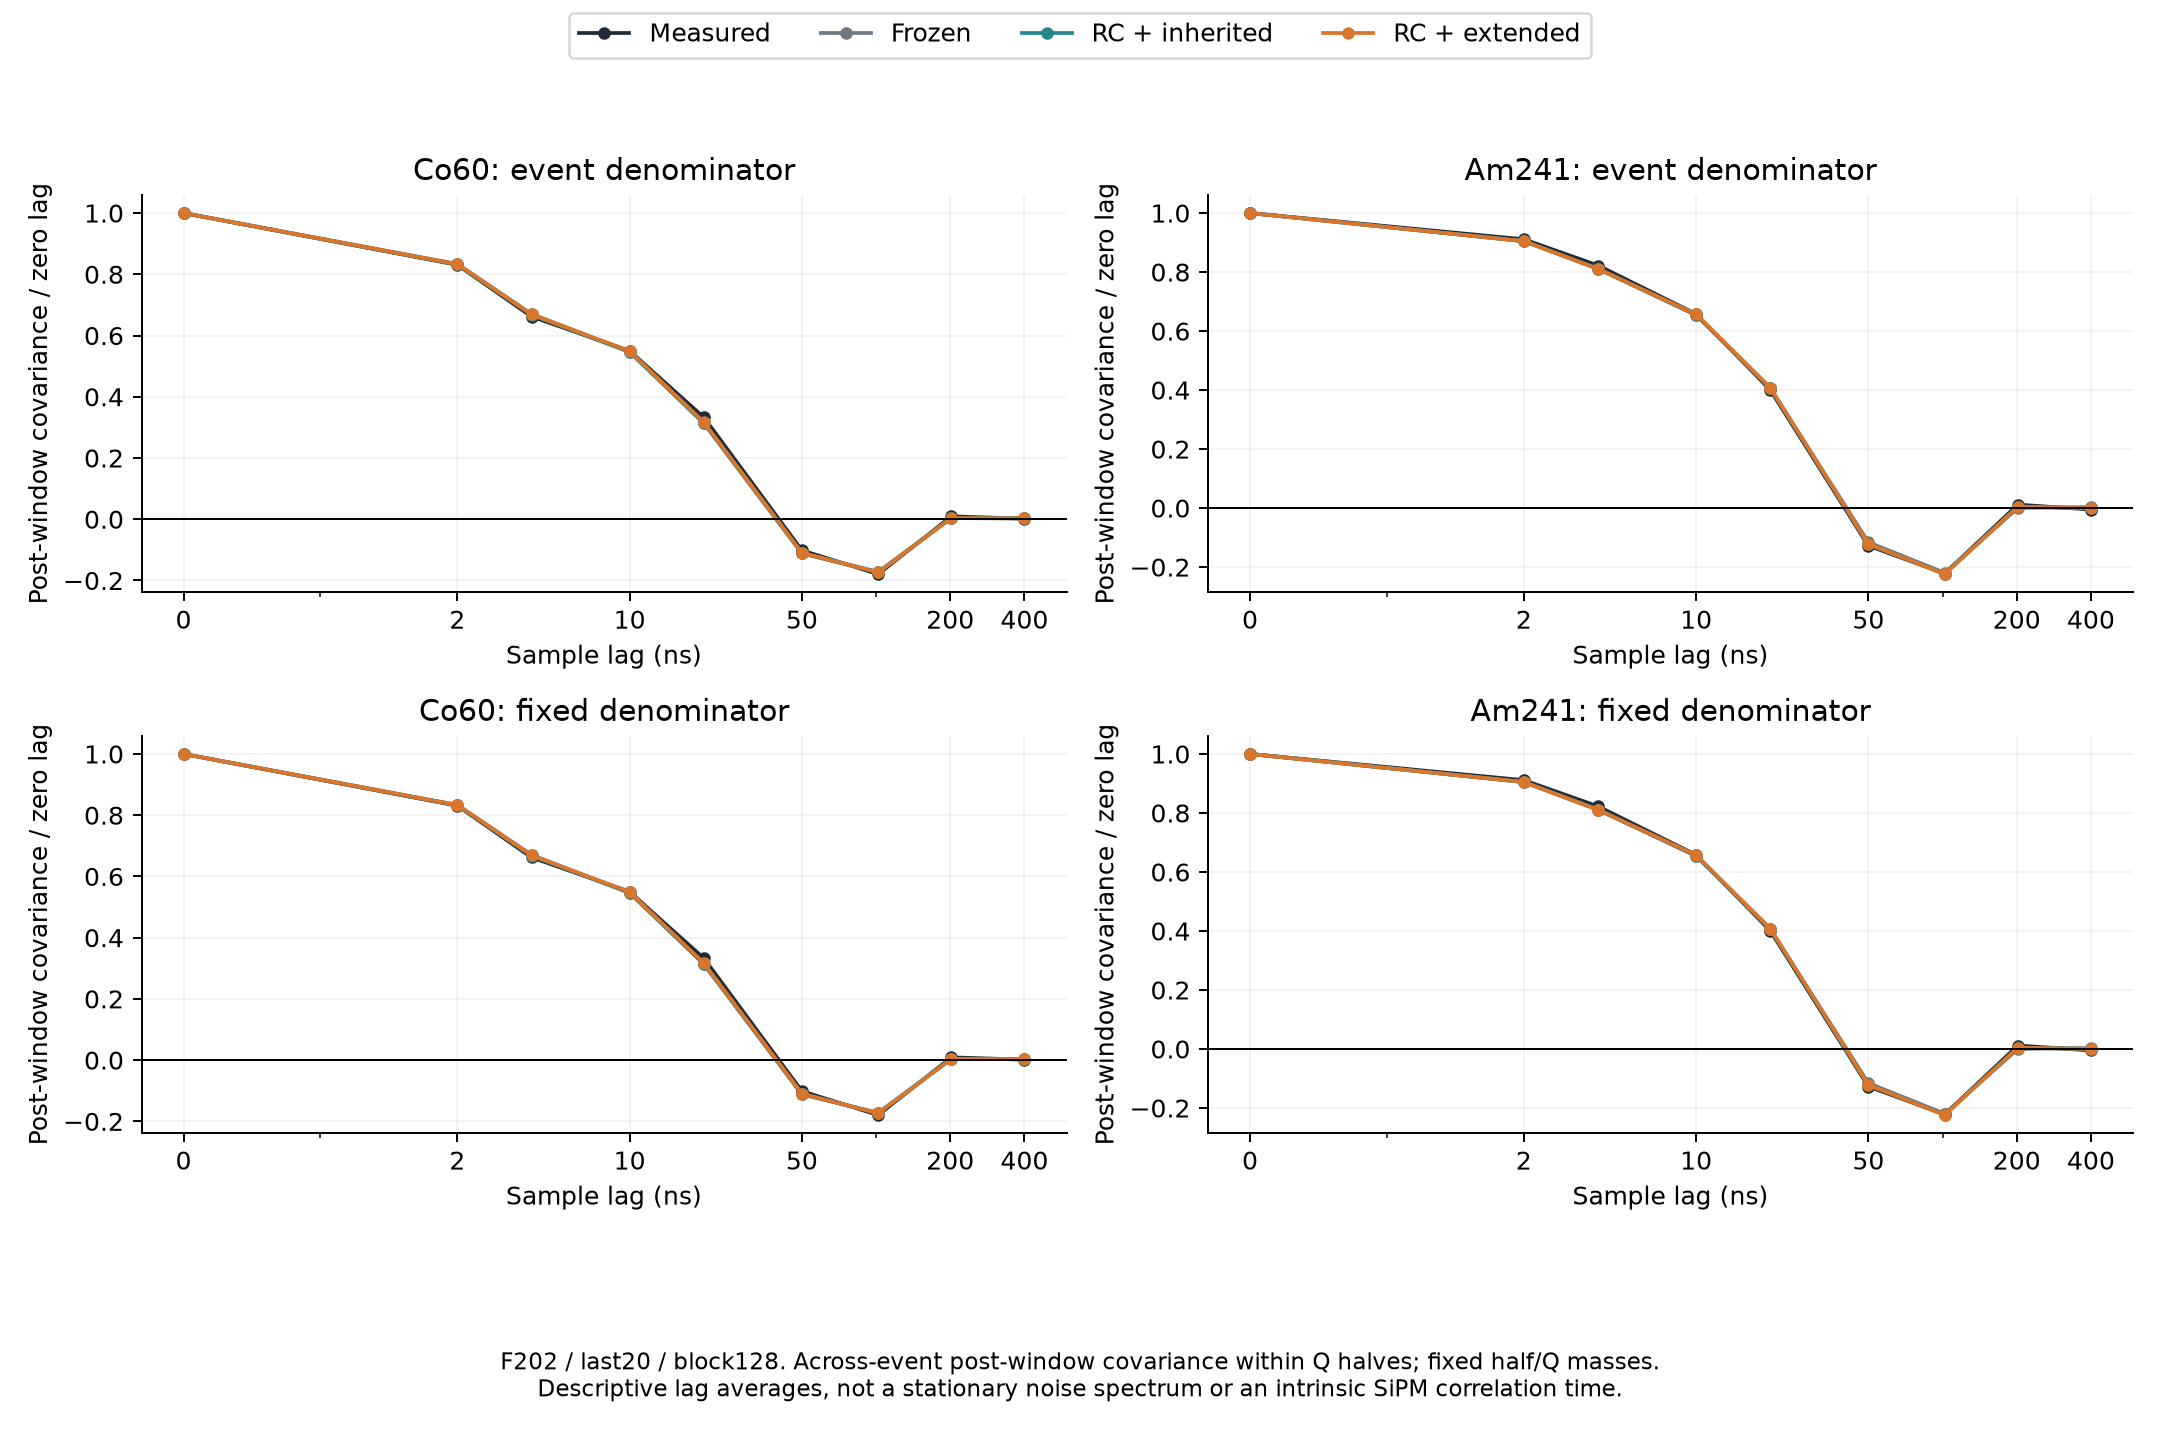

In [6]:
display(Image(filename=str(OUT/'figures/gaussian_temporal_covariance.png')))

## 5. 前、中、晚采集段与块长敏感性

全部12个源/采集段/块长条件、三个已有响应、三个尺度、两种分母和两种条件划分都保留。已有实验与MC已被多次诊断，此处不是盲验证。


|组|块长|直接SD比|Gaussian SD比|余项超额|重抽样范围|
|---|---|---|---|---|---|
|run3_first60|64|1.114|0.977|0.282|[0.155, 0.437] (512/512)|
|run3_first60|128|1.115|0.976|0.284|[0.179, 0.407] (512/512)|
|run3_middle20|64|1.093|0.986|0.219|[0.109, 0.474] (433/512)|
|run3_middle20|128|1.099|0.990|0.225|[0.127, 0.388] (404/512)|
|run3_last20|64|1.226|0.993|0.518|[0.343, 0.805] (507/512)|
|run3_last20|128|1.232|0.998|0.522|[0.377, 0.729] (503/512)|
|run12_first60|64|1.027|1.027|0.004|[-0.114, 0.133] (512/512)|
|run12_first60|128|0.988|1.029|-0.077|[-0.185, 0.045] (512/512)|
|run12_middle20|64|1.107|1.035|0.153|[-0.046, 0.402] (512/512)|
|run12_middle20|128|1.074|1.038|0.076|[-0.094, 0.275] (512/512)|
|run12_last20|64|1.181|1.039|0.299|[0.124, 0.550] (512/512)|
|run12_last20|128|1.201|1.039|0.348|[0.157, 0.593] (512/512)|

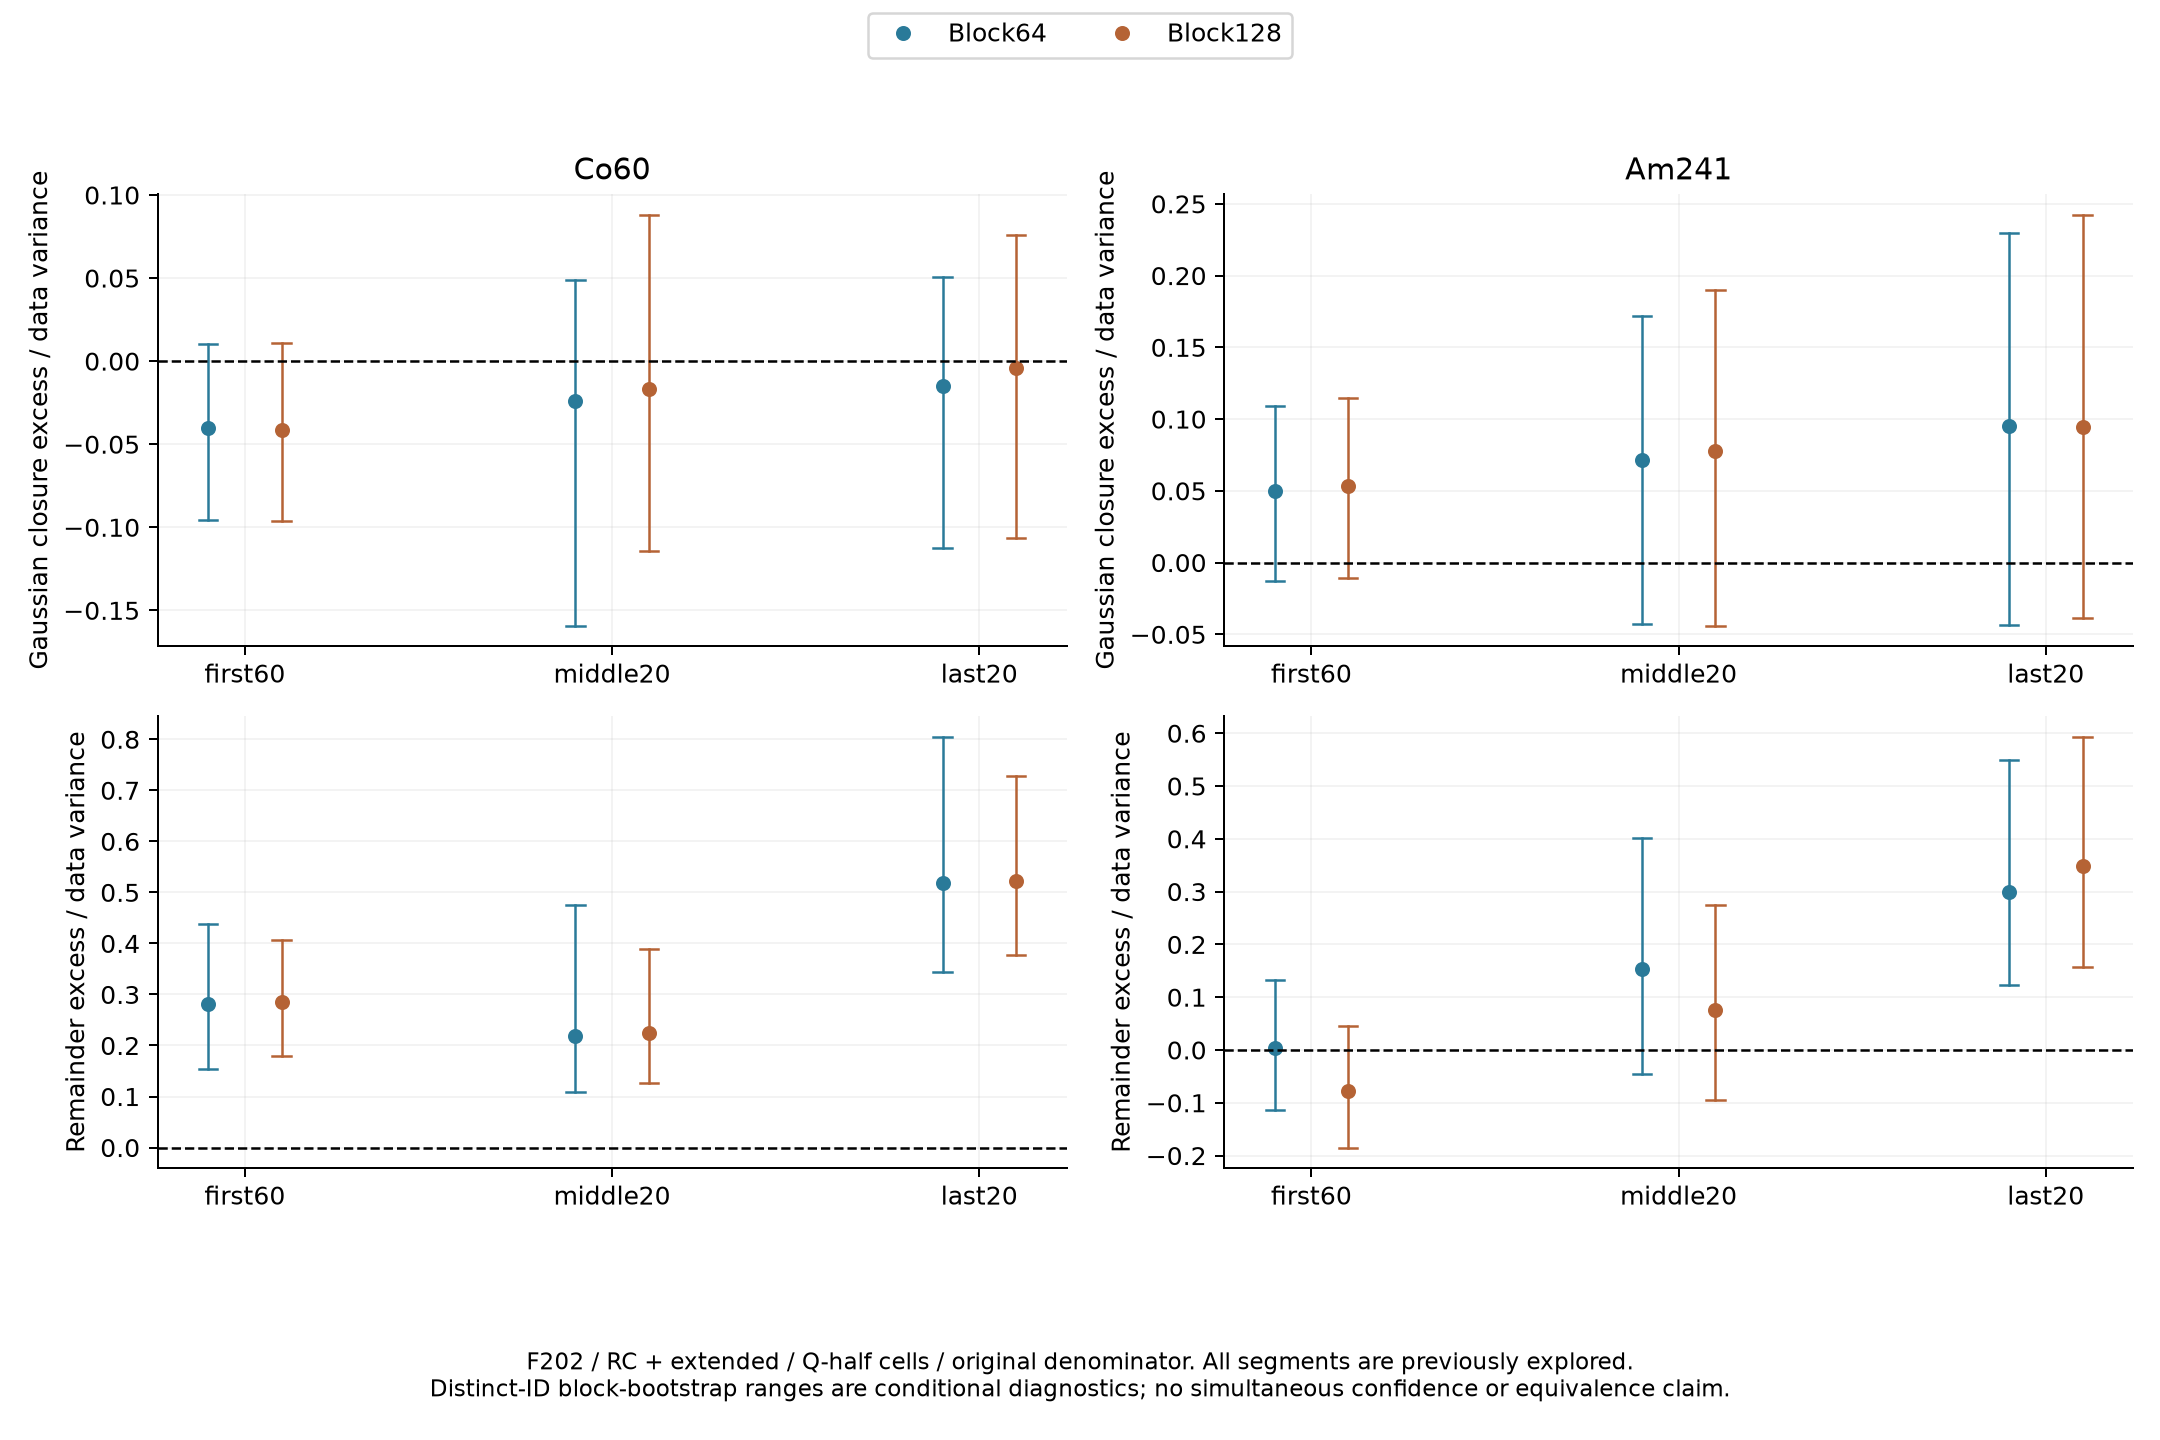

In [7]:
rows=[]
for group,blocks in e['groups'].items():
    for B,g in blocks.items():
        r=rec(g)
        rows.append([group,B,fmt(r['point']['observed_SD_ratio']),fmt(r['point']['gaussian_SD_ratio']),
                     fmt(r['point']['remainder_excess_over_data']),ci(r['CI95']['remainder_excess_over_data'])])
display(Markdown(table(['组','块长','直接SD比','Gaussian SD比','余项超额','重抽样范围'],rows)))
display(Image(filename=str(OUT/'figures/gaussian_segment_controls.png')))

## 6. 对下一轮建模的约束

F202与直接QDC/时间PID是不同指标。余项差异提供了检验方向，不能据此宣布正式PID带宽已解决，或把实验余项强行匹配到零。主带、电荷条件、触发及粒子混合本身也可能限制波动分布，需要与模型内信号相关方差的事件间异质性一起核查。


In [8]:
for finding in decision['findings_zh']:display(Markdown(finding))
display(Markdown(decision['next_work_zh']))
for limit in decision['limitations_zh']:display(Markdown('边界：'+limit))
print('结果目录:',OUT)
print('冻结与计算: simulation/analyze_gaussian_closure.py prepare; analyze --workers 2')
print('报告: simulation/report_gaussian_closure.py')
print('笔记: jupyter/codex_0001_build_gaussian_closure_notebook.py')
print('核验/封存: simulation/verify_gaussian_closure.py [--archive]')

结果目录: /media/sf_works/SiPM/simulation/results/gaussian_closure_20261102
冻结与计算: simulation/analyze_gaussian_closure.py prepare; analyze --workers 2
报告: simulation/report_gaussian_closure.py
笔记: jupyter/codex_0001_build_gaussian_closure_notebook.py
核验/封存: simulation/verify_gaussian_closure.py [--archive]


**Co60 晚段、块128、扩展谱、原分母：**直接F202 SD比为1.232，区间[1.168, 1.326]（512/512次有效）；Gaussian闭合的SD比为0.998，区间[0.951, 1.034]（503/512次有效）。以实测F202方差为单位，二阶闭合超额为-0.004，区间[-0.107, 0.076]（503/512次有效），余项超额为0.522，区间[0.377, 0.729]（503/512次有效）；二者相加严格等于直接方差超额。

**Co60 固定分母对照：**余项超额为0.483，区间[0.338, 0.689]（503/512次有效）；这里的分母来自既有对折实测参考，不用于修改ADC或正式PID。

**Am241 晚段、块128、扩展谱、原分母：**直接F202 SD比为1.201，区间[1.122, 1.312]（512/512次有效）；Gaussian闭合的SD比为1.039，区间[0.985, 1.100]（512/512次有效）。以实测F202方差为单位，二阶闭合超额为0.094，区间[-0.038, 0.242]（512/512次有效），余项超额为0.348，区间[0.157, 0.593]（512/512次有效）；二者相加严格等于直接方差超额。

**Am241 固定分母对照：**余项超额为0.227，区间[0.084, 0.420]（512/512次有效）；这里的分母来自既有对折实测参考，不用于修改ADC或正式PID。

扩展谱F202的全部12个采集段/块长条件中，余项超额的条件区间有8个完全大于0。它们共享事件并有多重比较，不能把该计数当作独立重复检验或显著性合并。

... (2 outputs left out)

边界：主分析保留响应折混合；细分Q半箱/折作为敏感性检查。Co中段和晚段部分格不足4个原事件，完整细分结果明确不可估计；不删除电荷箱、不将负U估计截成零。

边界：配对512次沿用父抽样计数；U项只使用不同原ID。有效次数不足512时，区间仅基于可估计抽样；没有严格覆盖率保证，稀疏Co低Q格尤其需要谨慎。

边界：所有均值、权重、对折参考和响应参数固定；区间不含重新拟合、装置系统误差或多重比较修正。已有实验和MC已经反复探索，不能称盲验证或宣称等效。

边界：Am数据包含α、γ与电子贡献；选择带及F诊断不是粒子真值或实验纯度。时间协方差曲线是描述性统计，不是直接测得的器件固有噪声谱。

`protocol.json`冻结方案、代码与339个输入哈希；`algebra_tests.json`记录不同有序元组的暴力枚举、直接协方差公式及Gaussian总体对照。

`kernels/`保存每个条件格的原事件索引、未归一化带符号Gram矩阵、固定分母与延迟曲线；`evaluation/`保存原512组计数、全部统计量/对比、逐Q点值与区间。`comparison_table.csv`共432行，`per_Q_table.csv`共1944行，`cell_counts.csv`共432行。`verification.json`核验独立卷积窗口、父指标逐次闭合、稀疏格传播与已执行笔记；`record.json`和源码快照封存结果。

本轮没有联网或修改共享文献库。Gaussian二次型代数在此直接推导并数值检验，不引用其他实验的成绩。重新完整运行应在新结果目录冻结方案，避免覆盖已有研究记录。
